In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open("names.txt", 'r').read().splitlines()
words[:5]

['emma', 'olivia', 'ava', 'isabella', 'sophia']

In [3]:
import string

chars = ['.'] + [char for char in string.ascii_lowercase]
stoi = {}

for i, char in enumerate(chars):
    stoi[char] = i

stoi

{'.': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

In [4]:
itos = {v:k for k, v in stoi.items()}
itos

{0: '.',
 1: 'a',
 2: 'b',
 3: 'c',
 4: 'd',
 5: 'e',
 6: 'f',
 7: 'g',
 8: 'h',
 9: 'i',
 10: 'j',
 11: 'k',
 12: 'l',
 13: 'm',
 14: 'n',
 15: 'o',
 16: 'p',
 17: 'q',
 18: 'r',
 19: 's',
 20: 't',
 21: 'u',
 22: 'v',
 23: 'w',
 24: 'x',
 25: 'y',
 26: 'z'}

In [5]:
window_size = 3
embedding_size = 10

def build_dataset(words):
    X, Y = [], []

    for word in words:
        w = "..." + word + "."
        for i in range(len(w)-window_size):
            x = [stoi[chr] for chr in w[i:i+window_size]]
            y = stoi[w[i+window_size]]
            X.append(x)
            Y.append(y)

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[n2:])
Xtr.shape

torch.Size([182625, 3])

In [82]:
hidden_layer_count = 300

g = torch.Generator().manual_seed(2147483647)
C = torch.randn(27, embedding_size, generator=g)
W1 = torch.randn(window_size*embedding_size, hidden_layer_count, generator=g) * ((5/3) / ((window_size*embedding_size)**0.5))
# b1 = torch.randn(hidden_layer_count, generator=g) * 0.01
W2 = torch.randn(hidden_layer_count, 27, generator=g) * 0.01 # Optimize the initial loss by making inital counts equal to zero
b2 = torch.randn(27, generator=g) * 0 # Optimize the initial loss by making inital counts equal to zero

bngain = torch.ones((1, hidden_layer_count))
bnbias = torch.zeros((1, hidden_layer_count))
bnmean_running = torch.zeros((1, hidden_layer_count))
bnstd_running = torch.ones((1, hidden_layer_count))

parameters = [C, W1, W2, b2, bngain, bnbias]

for p in parameters:
    p.requires_grad = True
bnbias.grad

In [88]:
# lre = torch.linspace(-3, 0, 1000)
# lrs = 10**lre
# lossi = []
# lri = []
learning_rate = 0.01

for i in range(10000):
    # Create batch
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # Forward pass
    emb = C[Xtr[ix]].view(-1, window_size*embedding_size)
    hpreact = emb @ W1
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    hpreact = bngain * ((hpreact - bnmeani) / bnstdi) + bnbias
    h = torch.tanh(hpreact)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    for p in parameters:
        p.grad = None

    # Backward pass
    loss.backward()

    # Gradient Descent
    for p in parameters:
        p.data += -learning_rate*p.grad

print(loss)

tensor(1.8141, grad_fn=<NllLossBackward0>)


(array([1084.,  393.,  311.,  273.,  196.,  198.,  176.,  177.,  147.,
         163.,  112.,  108.,  132.,  112.,  100.,  118.,   89.,   98.,
         100.,  117.,  109.,   94.,   94.,   93.,  119.,  101.,   98.,
          78.,   88.,  113.,   85.,  121.,  102.,  103.,  140.,   99.,
         118.,  108.,  135.,  127.,  148.,  149.,  174.,  172.,  181.,
         210.,  246.,  368.,  482., 1141.]),
 array([-9.99997437e-01, -9.59997711e-01, -9.19997985e-01, -8.79998260e-01,
        -8.39998534e-01, -7.99998808e-01, -7.59999082e-01, -7.19999356e-01,
        -6.79999630e-01, -6.39999905e-01, -6.00000179e-01, -5.60000453e-01,
        -5.20000727e-01, -4.80001001e-01, -4.40001276e-01, -4.00001550e-01,
        -3.60001824e-01, -3.20002098e-01, -2.80002372e-01, -2.40002646e-01,
        -2.00002921e-01, -1.60003195e-01, -1.20003469e-01, -8.00037432e-02,
        -4.00040174e-02, -4.29153442e-06,  3.99954343e-02,  7.99951601e-02,
         1.19994886e-01,  1.59994612e-01,  1.99994338e-01,  2.399940

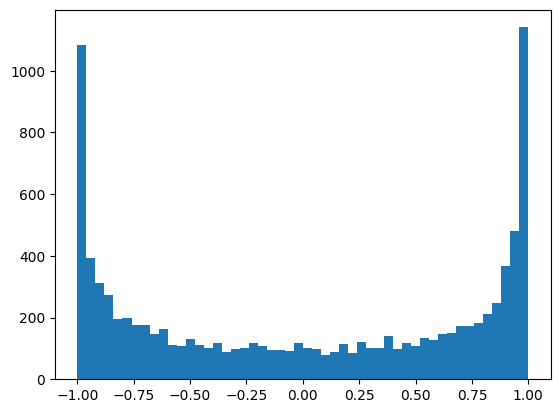

In [57]:
plt.hist(h.view(-1).tolist(), 50)

(array([  1.,   4.,   1.,   1.,   0.,   5.,   5.,   8.,   8.,  19.,  26.,
         41.,  52.,  67.,  91., 130., 169., 202., 286., 279., 357., 436.,
        504., 565., 551., 628., 610., 640., 575., 557., 481., 394., 411.,
        355., 280., 239., 162., 125.,  99.,  62.,  41.,  36.,  37.,  24.,
         24.,   3.,   2.,   3.,   2.,   2.]),
 array([-6.78101301, -6.52439557, -6.26777813, -6.01116069, -5.75454325,
        -5.49792581, -5.24130836, -4.98469092, -4.72807348, -4.47145604,
        -4.2148386 , -3.95822116, -3.70160372, -3.44498628, -3.18836884,
        -2.93175139, -2.67513395, -2.41851651, -2.16189907, -1.90528163,
        -1.64866419, -1.39204675, -1.13542931, -0.87881186, -0.62219442,
        -0.36557698, -0.10895954,  0.1476579 ,  0.40427534,  0.66089278,
         0.91751022,  1.17412766,  1.43074511,  1.68736255,  1.94397999,
         2.20059743,  2.45721487,  2.71383231,  2.97044975,  3.22706719,
         3.48368464,  3.74030208,  3.99691952,  4.25353696,  4.5101544 ,
 

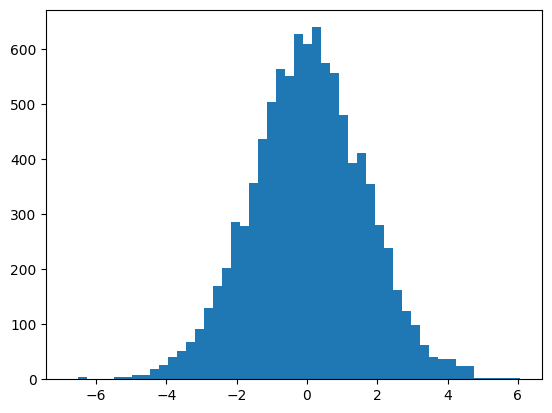

In [58]:
plt.hist(hpreact.view(-1).tolist(), 50)

torch.Size([30, 300])

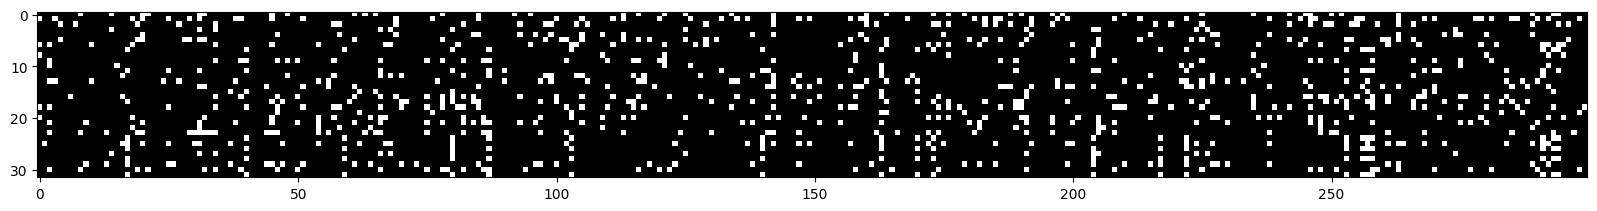

In [59]:
plt.figure(figsize=(20, 10))
plt.imshow(h.abs()>0.99, cmap='gray', interpolation='nearest')
W1.shape

In [89]:
emb = C[Xdev].view(-1, window_size*embedding_size)
hpreact = emb @ W1
hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbias
h = torch.tanh(hpreact)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
print(loss)
print(logits.exp())

tensor(2.1246, grad_fn=<NllLossBackward0>)
tensor([[1.9799e-02, 6.4396e+00, 1.6882e+00,  ..., 2.1260e-01, 7.7916e-01,
         1.3191e+00],
        [4.5323e-02, 2.3166e+00, 1.9660e+00,  ..., 3.1079e-01, 2.4632e+00,
         1.6072e+00],
        [1.8762e-01, 4.1447e+01, 5.0791e+00,  ..., 1.8616e-01, 9.1614e+00,
         7.8911e-01],
        ...,
        [6.5816e+00, 1.4190e+01, 8.9820e-01,  ..., 2.1823e-01, 4.7622e-01,
         1.9238e+00],
        [5.8935e+00, 1.9408e+02, 3.8704e-01,  ..., 5.6230e-02, 5.0551e+01,
         1.4299e-01],
        [1.1945e+02, 2.1750e+00, 5.5523e-01,  ..., 7.2291e-02, 2.0543e+00,
         1.6543e-01]], grad_fn=<ExpBackward0>)


In [90]:
for _ in range(20):
    out = []
    context = [0] * window_size
    
    while True:
        emb = C[torch.tensor([context])].view(-1, window_size*embedding_size)
        hpreact = emb @ W1
        hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbias
        h = torch.tanh(hpreact)
        logits = h @ W2 + b2 
        probs = F.softmax(logits, dim=1)
        ix = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)

        if ix == 0:
            break
    
    print(''.join([itos[ix] for ix in out]))

kei.
emileen.
hai.
lynn.
sjaula.
bric.
csopero.
patt.
calvie.
xesten.
bakulee.
hudryc.
jestogen.
chny.
den.
anny.
azana.
davaoluwathorve.
rema.
leris.


In [92]:
class Linear():
    
    def __init__(self, fan_in, fan_out, bias=True):
        self.weights = torch.randn(fan_in, fan_out, generator=g) / fan_in**0.5
        self.bias = torch.zeros(fan_out) if bias else None
    
    def __call__(self, inputs):
        self.out = inputs @ self.weights

        if self.bias is not None:
            self.out += self.bias
        
        return self.out
    
    def parameters(self):
        return [self.weights] + ([self.bias] if self.bias is not None else [])

class BatchNorm1d():

    def __init__(self, num_features, eps=1e-05, momentum=0.1, track_running_stats=True):
        self.gamma = torch.ones(num_features)
        self.beta = torch.zeros(num_features)
        self.eps = eps
        self.momentum = momentum
        self.track_running_stats = track_running_stats
        self.running_mean = torch.zeros(num_features)
        self.running_var = torch.ones(num_features)
    
    def __call__(self, inputs):
        if self.track_running_stats:
            mean = inputs.mean(0, keepdim=True)
            var = inputs.var(0, keepdim=True, unbiased=True)
        else:
            mean = self.running_mean
            var = self.running_var
        
        self.out = self.gamma * (inputs - mean) / torch.sqrt(var + self.eps) + self.beta

        if self.track_running_stats:
            with torch.no_grad():
                self.running_mean = (1-self.momentum) * self.running_mean + self.momentum * mean
                self.running_var = (1-self.momentum) * self.running_var + self.momentum * var
        
        return self.out
    
    def parameters(self):
        return [self.gamma, self.beta]

class Tanh():

    def __call__(self, inputs):
        self.out = torch.tanh(inputs)
        return self.out
    
    def parameters(self):
        return []

        
window_size = 3
embedding_size = 10
hidden_layer_count = 100
vocab_size = 27

g = torch.Generator().manual_seed(2147483647)
C = torch.randn(vocab_size, embedding_size, generator=g)

layers = [
    Linear(window_size*embedding_size, hidden_layer_count), Tanh(),
    Linear(hidden_layer_count, hidden_layer_count), Tanh(),
    Linear(hidden_layer_count, hidden_layer_count), Tanh(),
    Linear(hidden_layer_count, hidden_layer_count), Tanh(),
    Linear(hidden_layer_count, hidden_layer_count), Tanh(),
    Linear(hidden_layer_count, vocab_size),
]

with torch.no_grad():
    # make last layer less confident
    layers[-1].weights *= 0.1
    # apply gain in all other layers
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weights *= 5/3

parameters = [C] + [parameter for layer in layers for parameter in layer.parameters()]
print(sum(p.nelement() for p in parameters))

for p in parameters:
    p.requires_grad = True

46497
